# Final scores and station qc

Final scoring with ERA5 included; Coop vs ASOS gauge-network check; effect of a 2-year validity rule.

Cells are the original session code in execution order (exported verbatim; only secrets handling and artifact paths were changed). Each cell starts with a comment giving its original index, conda environment and run status. Exploratory and failed cells are kept, so later cells that rely on their partial state still make sense.


In [ ]:
# Setup: run from the repository root; helper modules live in prod/
import os, sys
if os.path.basename(os.getcwd())=='notebooks': os.chdir('..')
sys.path.insert(0, 'prod')
os.makedirs('out', exist_ok=True)
from style import apply_figure_style  # stand-in for the figure style used in the session


In [168]:
# [orig cell 167 | env: precip | status: ok]
PRODS={'mrms_gaugecorr':'MRMS gauge-corrected (1 km)','mrms_radaronly':'MRMS radar-only (1 km)','stage4':'Stage IV (4 km)','nldas2':'NLDAS-2 (0.125°)',
       'pccs':'PERSIANN-CCS (0.04°)','cmorph':'CMORPH CDR (8 km)','imerg':'IMERG V07 Final (0.1°)','era5':'ERA5 (0.25°)','merra2':'MERRA-2 (0.5°×0.625°)'}
PTYPE['era5']='atmospheric reanalysis'
avail=list(PRODS)
SCa,PEa,NBall=run(avail)
PEa['key']=PEa.event_id
cnt=PEa[PEa.nbhd=='N1'].groupby(['threshold','key']).product.nunique()
COMMON_EV=set(cnt[cnt==len(avail)].index)
print({T:sum(1 for t,k in COMMON_EV if t==T) for T in EV})
PEc=PEa[[(t,k) in COMMON_EV for t,k in zip(PEa.threshold,PEa.key)]].copy()
PEc['hit']=PEc.prod_0h>=PEc.threshold; PEc['hit_pm1']=PEc.prod_pm1h>=PEc.threshold
PEc['hit10']=PEc.prod_0h>=10; PEc['hit1']=PEc.prod_0h>=1; PEc['ratio']=PEc.prod_0h/PEc.peak_mm_h
rng=np.random.default_rng(1); rows=[]
for (p,T,N),d in PEc.groupby(['product','threshold','nbhd']):
    lo,hi=boot_ci(d,'hit')
    rows.append(dict(product=p,label=PRODS[p],type=PTYPE[p],threshold=T,nbhd=N,n_events=len(d),hit_strict=d.hit.mean(),hit_strict_lo=lo,hit_strict_hi=hi,
                     hit_strict_pm1h=d.hit_pm1.mean(),hit_ge10=d.hit10.mean(),hit_ge1=d.hit1.mean(),
                     ratio_median=d.ratio.median(),ratio_q25=d.ratio.quantile(.25),ratio_q75=d.ratio.quantile(.75)))
DS=pd.DataFrame(rows).merge(SCa[['product','threshold','nbhd','POD_h','FAR_h','CSI_h','FBI_h','n_hours']],on=['product','threshold','nbhd'])
DS['o']=DS['product'].map({p:i for i,p in enumerate(PRODS)}); DS=DS.sort_values(['threshold','o','nbhd']).drop(columns='o')
DS.to_csv('out/detection_scores.csv',index=False)
print(DS[DS['product']=='era5'][['threshold','nbhd','hit_strict','hit_ge10','hit_ge1','ratio_median','CSI_h']].round(3).to_string(index=False))
print(DS[DS.nbhd=='N1'].pivot_table(index='label',columns='threshold',values='hit_strict',sort=False).round(3))

{20: 6950, 30: 2769, 40: 1055, 50: 446}
 threshold nbhd  hit_strict  hit_ge10  hit_ge1  ratio_median  CSI_h
        20   N1       0.001     0.016    0.410         0.020  0.003
        20  N16       0.006     0.073    0.719         0.090  0.012
        20   N4       0.003     0.032    0.547         0.043  0.007
        20   N9       0.005     0.056    0.650         0.068  0.010
        30   N1       0.000     0.019    0.430         0.016  0.000
        30  N16       0.001     0.084    0.745         0.073  0.001
        30   N4       0.000     0.037    0.573         0.036  0.000
        30   N9       0.000     0.066    0.678         0.057  0.000
        40   N1       0.000     0.025    0.444         0.014  0.000
        40  N16       0.000     0.083    0.765         0.061  0.000
        40   N4       0.000     0.040    0.592         0.031  0.000
        40   N9       0.000     0.066    0.693         0.048  0.000
        50   N1       0.000     0.027    0.442         0.012  0.000
        

In [169]:
# [orig cell 168 | env: precip | status: ok]
rows=[]
for T in [20,30,50]:
    for N in ['N1','N9']:
        d0=PEc[(PEc.threshold==T)&(PEc.nbhd==N)].copy()
        d0['gauge_network']=d0.STATION.map(Vst.set_index('id').source_group).map({'metar':'ASOS/METAR','onhour':'Coop HPD/other'})
        for c in conds+['gauge_network']:
            for (lev,p),dp in d0.groupby([c,'product']):
                n=len(dp); h=dp.hit.mean()
                rows.append(dict(threshold=T,nbhd=N,condition=c,level=lev,product=p,label=PRODS[p],n_events=n,n_stations=dp.STATION.nunique(),
                                 hit_strict=h,hit_se=np.sqrt(h*(1-h)/n),hit_ge10=dp.hit10.mean(),ratio_median=dp.ratio.median()))
CS=pd.DataFrame(rows); CS.to_csv('out/conditional_scores.csv',index=False)
x=CS[(CS.threshold==20)&(CS.nbhd=='N1')&(CS['product']=='era5')][['condition','level','hit_ge10','ratio_median']]
print(x.round(3).to_string(index=False))

    condition                            level  hit_ge10  ratio_median
   storm_type            Cool-season (frontal)     0.015         0.045
   storm_type                 Tropical cyclone     0.108         0.076
   storm_type  Warm-season isolated convection     0.006         0.008
   storm_type Warm-season organized (MCS-like)     0.013         0.025
       season                    Dry (Nov–Apr)     0.014         0.046
       season                    Wet (May–Oct)     0.016         0.015
  time_of_day                  Afternoon 12–18     0.020         0.032
  time_of_day                    Evening 18–24     0.010         0.007
  time_of_day                    Morning 06–12     0.006         0.024
  time_of_day                      Night 00–06     0.031         0.020
       region                          Central     0.019         0.020
       region                            North     0.022         0.014
       region                        Panhandle     0.012         0.030
      

0
3
0


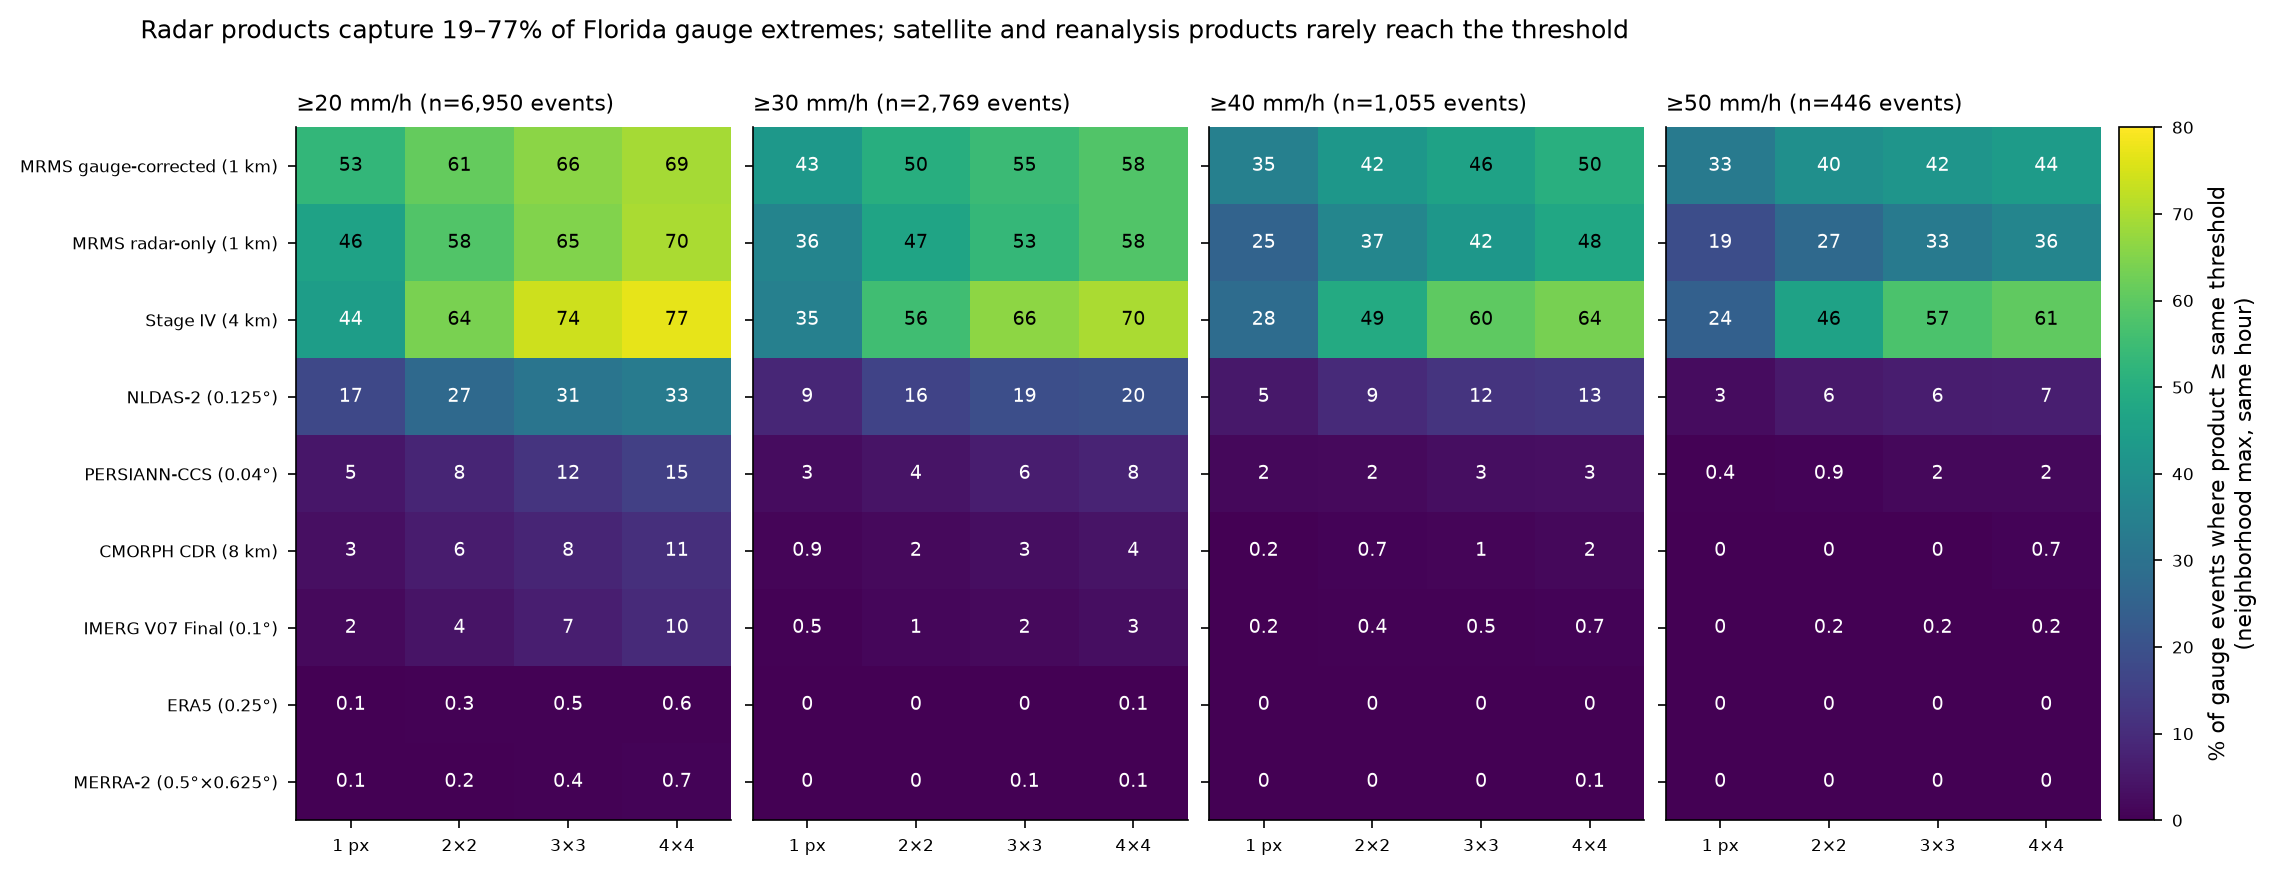

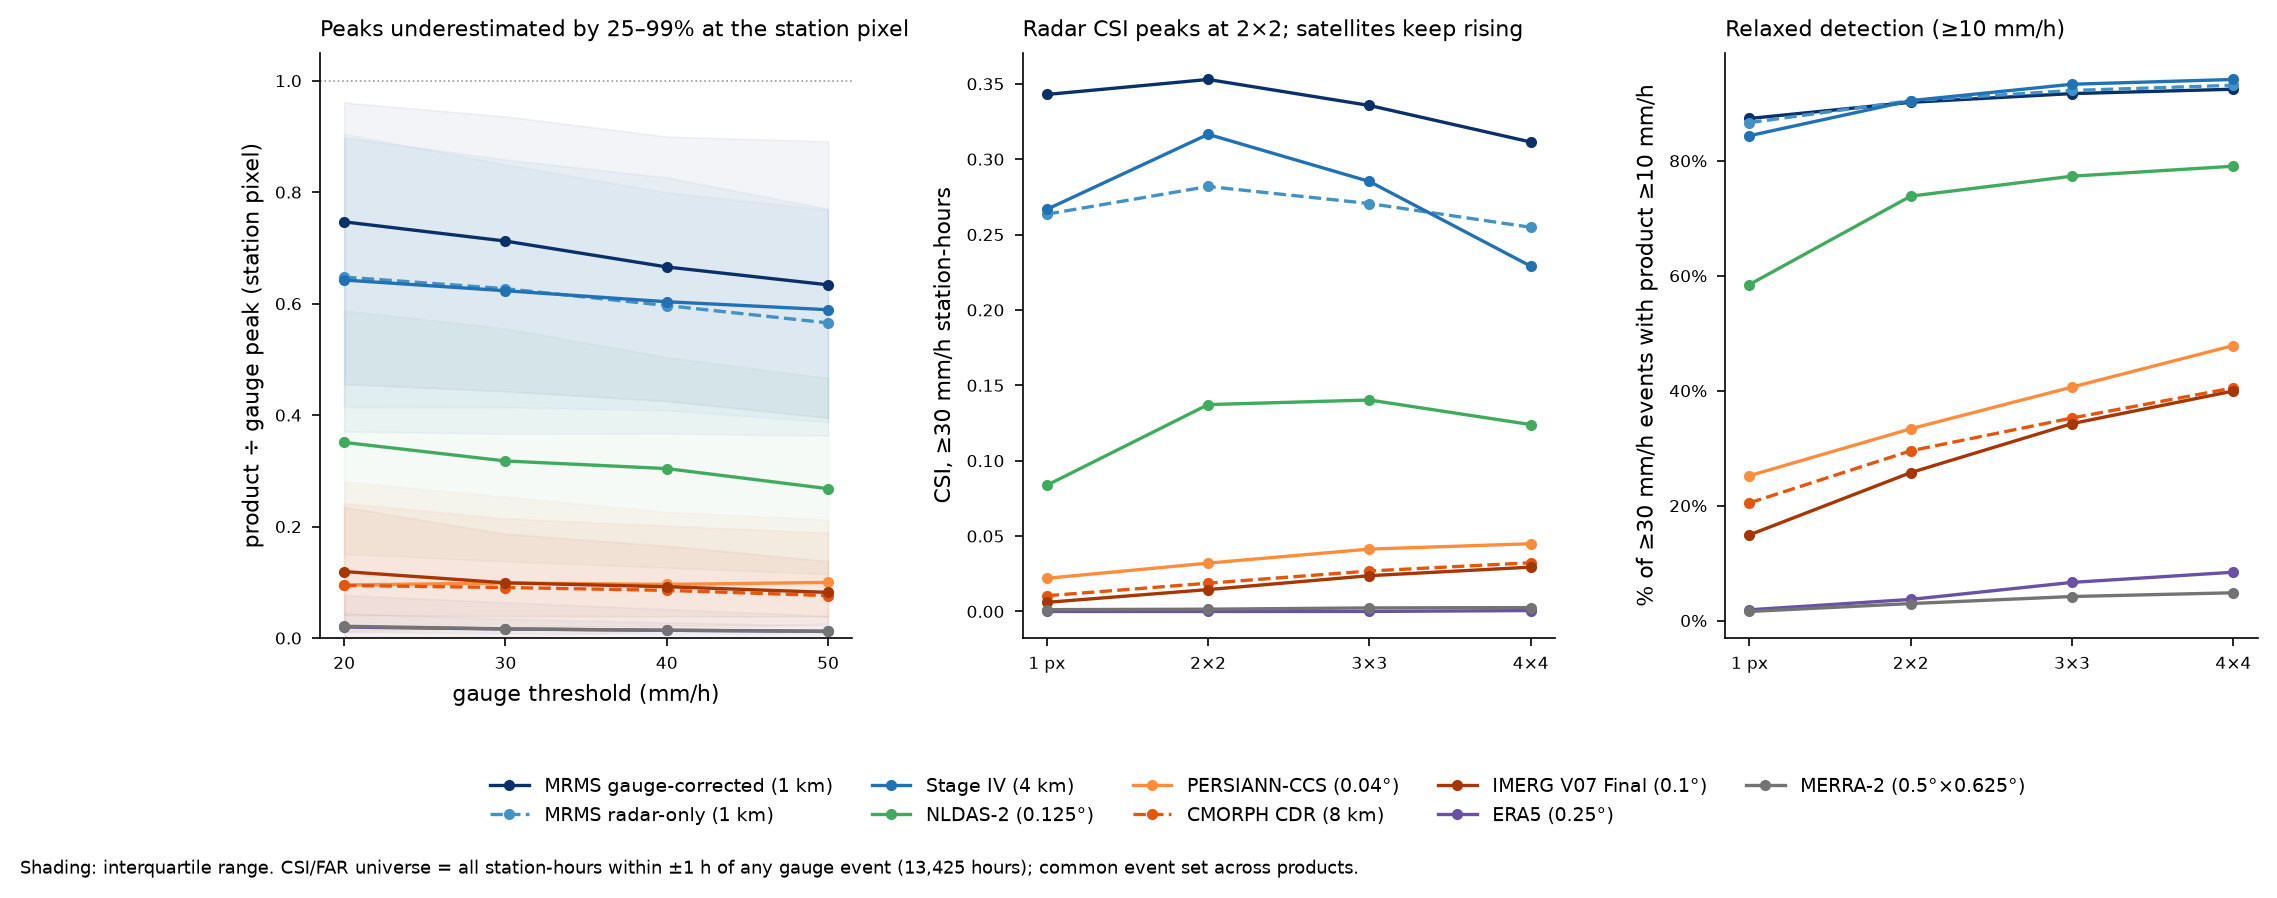

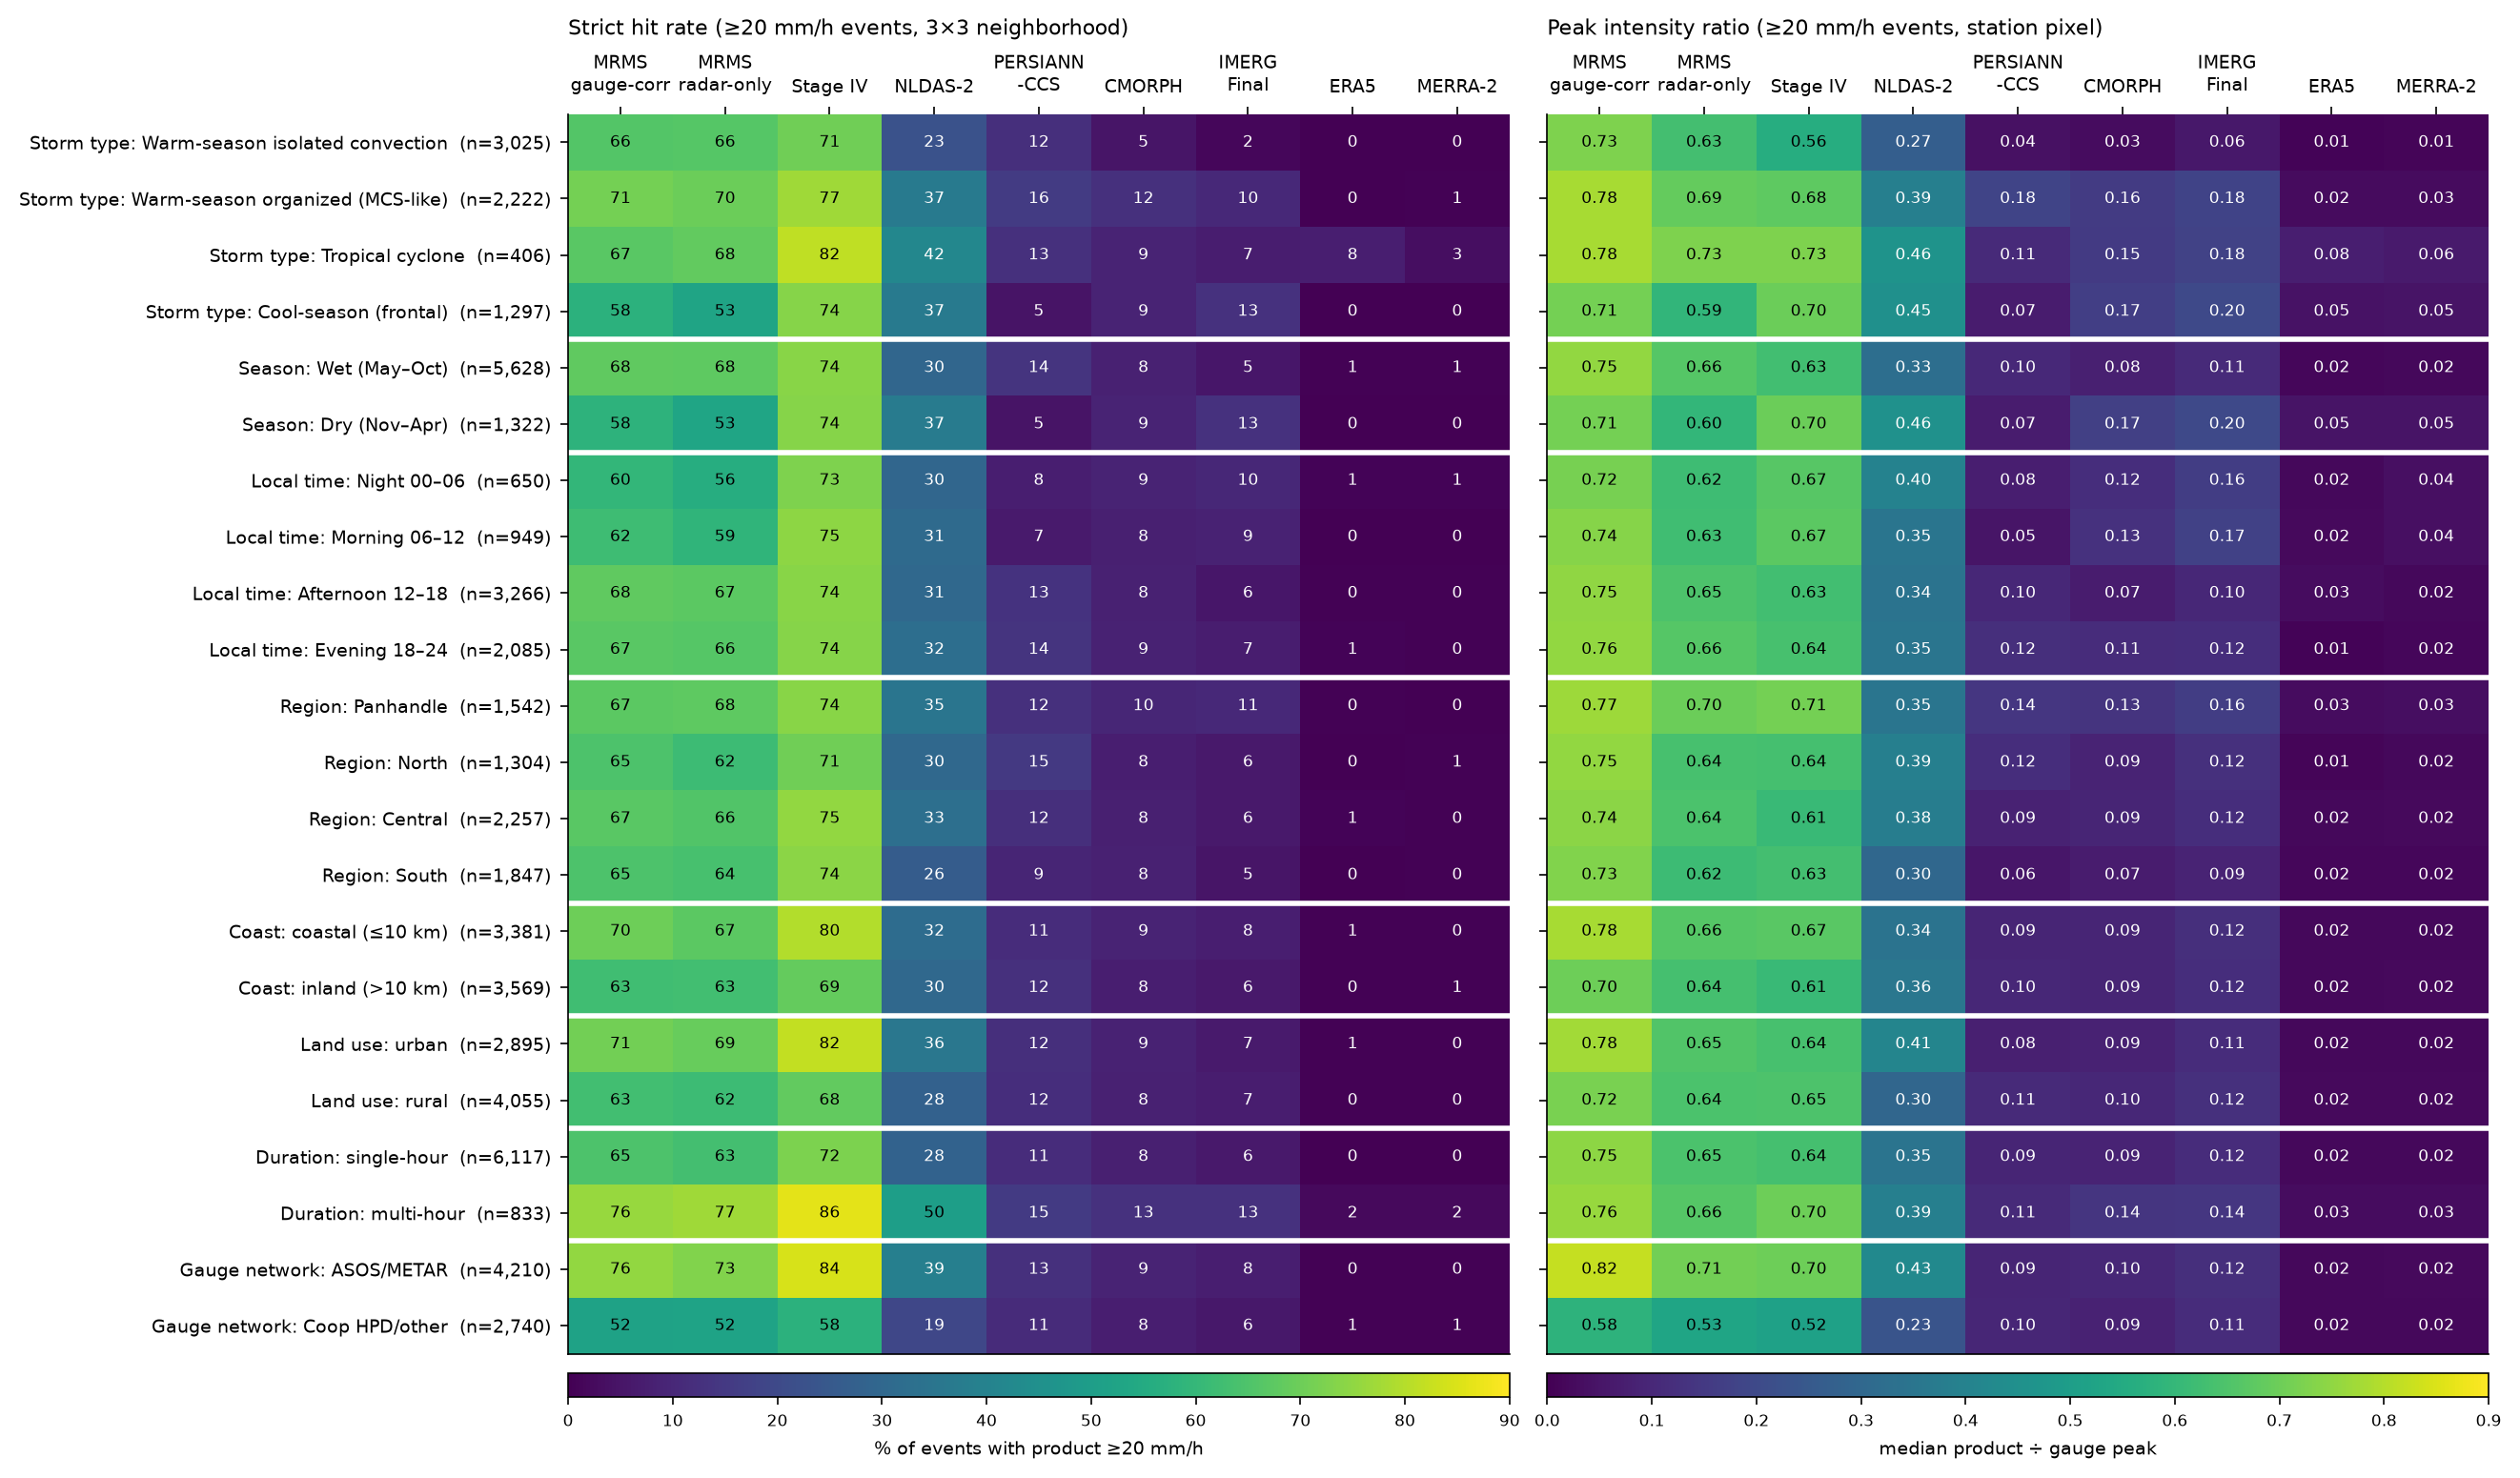

In [170]:
# [orig cell 169 | env: precip | status: ok]
labs=[PRODS[p] for p in PRODS]
fig,axs=plt.subplots(1,4,figsize=(12,4.5),sharey=True,gridspec_kw=dict(wspace=0.05))
for ax,T in zip(axs,[20,30,40,50]):
    M=DS[DS.threshold==T].pivot_table(index='label',columns='nbhd',values='hit_strict',sort=False).reindex(index=labs,columns=Ns)
    im=ax.imshow(M.values*100,cmap='viridis',vmin=0,vmax=80,aspect='auto')
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v=M.values[i,j]*100; ax.text(j,i,f'{v:.0f}' if v>=1 else (f'{v:.1f}' if v>0 else '0'),ha='center',va='center',fontsize=7,color='w' if v<45 else 'k')
    n=int(DS[(DS.threshold==T)].n_events.iloc[0]); ax.set_xticks(range(4)); ax.set_xticklabels(Nlab); ax.set_title(f'≥{T} mm/h (n={n:,} events)',loc='left')
axs[0].set_yticks(range(len(labs))); axs[0].set_yticklabels(labs)
cb=fig.colorbar(im,ax=axs,fraction=0.02,pad=0.01); cb.set_label('% of gauge events where product ≥ same threshold\n(neighborhood max, same hour)')
fig.suptitle('Radar products capture 19–77% of Florida gauge extremes; satellite and reanalysis products rarely reach the threshold',x=0.06,ha='left',y=1.0,fontsize=9)
fig.savefig('out/detection_heatmaps.png',dpi=200,bbox_inches='tight')
pc['era5']='#6a51a3'; pls['era5']='-'
fig2,ax=plt.subplots(1,3,figsize=(12.5,3.8),gridspec_kw=dict(wspace=0.32))
for p in PRODS:
    d=DS[(DS['product']==p)&(DS.nbhd=='N1')]
    ax[0].plot(d.threshold,d.ratio_median,ls=pls[p],marker='o',ms=3,color=pc[p],label=PRODS[p]); ax[0].fill_between(d.threshold,d.ratio_q25,d.ratio_q75,color=pc[p],alpha=0.05)
    d3=DS[(DS['product']==p)&(DS.threshold==30)].set_index('nbhd').reindex(Ns)
    ax[1].plot(range(4),d3.CSI_h,ls=pls[p],marker='o',ms=3,color=pc[p]); ax[2].plot(range(4),d3.hit_ge10,ls=pls[p],marker='o',ms=3,color=pc[p])
ax[0].axhline(1,color='0.6',lw=0.6,ls=':'); ax[0].set_xticks([20,30,40,50]); ax[0].set_xlabel('gauge threshold (mm/h)'); ax[0].set_ylabel('product ÷ gauge peak (station pixel)')
ax[0].set_title('Peaks underestimated by 25–99% at the station pixel',loc='left'); ax[0].set_ylim(0,1.05)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(Nlab); ax[1].set_ylabel('CSI, ≥30 mm/h station-hours'); ax[1].set_title('Radar CSI peaks at 2×2; satellites keep rising',loc='left')
ax[2].set_xticks(range(4)); ax[2].set_xticklabels(Nlab); ax[2].set_ylabel('% of ≥30 mm/h events with product ≥10 mm/h'); ax[2].set_title('Relaxed detection (≥10 mm/h)',loc='left')
ax[2].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
for a in ax: a.margins(x=0.05)
hh,ll=ax[0].get_legend_handles_labels(); fig2.legend(hh,ll,loc='lower center',ncol=5,frameon=False,fontsize=7,bbox_to_anchor=(0.5,-0.16))
fig2.text(0.005,-0.2,'Shading: interquartile range. CSI/FAR universe = all station-hours within ±1 h of any gauge event (13,425 hours); common event set across products.',fontsize=6.5)
fig2.savefig('out/detection_intensity_csi.png',dpi=200,bbox_inches='tight')
short['era5']='ERA5'
A1,idx,nn=mat(20,'N9','hit_strict'); A2,_,_=mat(20,'N1','ratio_median')
fig3,axs=plt.subplots(1,2,figsize=(13,8.8),sharey=True,gridspec_kw=dict(wspace=0.04))
for ax_,A,ttl,vmax,fmt_,cbl in [(axs[0],A1*100,'Strict hit rate (≥20 mm/h events, 3×3 neighborhood)',90,'{:.0f}','% of events with product ≥20 mm/h'),(axs[1],A2,'Peak intensity ratio (≥20 mm/h events, station pixel)',0.9,'{:.2f}','median product ÷ gauge peak')]:
    im=ax_.imshow(A,cmap='viridis',vmin=0,vmax=vmax,aspect='auto')
    for i in range(A.shape[0]):
        for j in range(A.shape[1]): ax_.text(j,i,fmt_.format(A[i,j]),ha='center',va='center',fontsize=6.3,color='w' if A[i,j]<0.55*vmax else 'k')
    ax_.set_xticks(range(len(PRODS))); ax_.set_xticklabels([short[p] for p in PRODS],fontsize=7); ax_.xaxis.tick_top(); ax_.set_title(ttl,loc='left',pad=30,fontsize=8)
    b=0
    for c in corder[:-1]: b+=len(lvl_order[c]); ax_.axhline(b-0.5,color='w',lw=2)
    cb=fig3.colorbar(im,ax=ax_,orientation='horizontal',fraction=0.025,pad=0.015,aspect=40); cb.set_label(cbl,fontsize=7)
axs[0].set_yticks(range(len(idx))); axs[0].set_yticklabels([f'{cname[c]}: {l}  (n={n:,})' for (c,l),n in zip(idx,nn)],fontsize=7)
fig3.savefig('out/conditional_skill.png',dpi=200,bbox_inches='tight')
for F in [fig,fig2,fig3]:
    r=F.canvas.get_renderer(); tx=[t for t in F.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]; bb=[t.get_window_extent(r) for t in tx]
    print(len([(i,j) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j])]))

In [171]:
# [orig cell 170 | env: precip | status: ok]
nd=[]
for p in PRODS:
    w=NBall[p][1]['widx']; dx=np.median([x['dx_km'] for x in w if x['ok']]); dy=np.median([x['dy_km'] for x in w if x['ok']])
    for N,k in [('N1',1),('N4',2),('N9',3),('N16',4)]:
        nd.append(dict(product=p,label=PRODS[p],type=PTYPE[p],pixel_dx_km=round(dx,2),pixel_dy_km=round(dy,2),nbhd=N,block=f'{k}x{k}',side_km=round(k*np.sqrt(dx*dy),1),area_km2=round(k*k*dx*dy,1),stations_covered=sum(x['ok'] for x in w)))
pd.DataFrame(nd).to_csv('out/neighborhood_definitions.csv',index=False)
LAGNOTE={'nldas2':'+1 h shift (file stamp = hour end)','era5':'stamp = hour end; converted to hour start','stage4':'stamp = hour end; converted','mrms_gaugecorr':'stamp = hour end; converted','mrms_radaronly':'stamp = hour end; converted'}
pd.DataFrame({'product':list(PRODS),'applied_extra_lag_h':[LAG.get(p,0) for p in PRODS],'note':[LAGNOTE.get(p,'stamp = hour start') for p in PRODS]}).to_csv('out/product_time_alignment.csv',index=False)
recs=[]
for p in PRODS:
    NB=NBall[p][0]; d={'hour_start_utc':np.repeat(Hneed.values[inH1],len(Vst)),'station':np.tile(Vst.id.values,inH1.sum())}
    for kk,v in NB.items(): d[kk]=v[inH1].ravel().astype(np.float32)
    df=pd.DataFrame(d); df=df[df.N1max.notna()]; df.insert(0,'product',p); recs.append(df)
NBH=pd.concat(recs); NBH['product']=NBH['product'].astype('category'); NBH['station']=NBH.station.astype('category')
NBH.to_parquet('out/product_neighborhood_hourly.parquet',compression='zstd')
PEa.drop(columns=['key']).to_parquet('out/event_product_values.parquet',compression='zstd'); print(NBH['product'].nunique(), PEa['product'].nunique())

9 9


In [172]:
# [orig cell 171 | env: precip | status: ok]
L=[main_table.split('\n')[0],main_table.split('\n')[1]]
for p in PRODS:
    r=lambda T,N: DS[(DS['product']==p)&(DS.threshold==T)&(DS.nbhd==N)].iloc[0]
    cs=DS[(DS['product']==p)&(DS.threshold==30)].set_index('nbhd').CSI_h; cells=[]
    for T in [20,30,50]:
        for N in ['N1','N16']:
            x=r(T,N); dg=0 if x.hit_strict>=0.1 else 1
            cells.append(f"{fmt(x.hit_strict,dg)}% ({fmt(x.hit_strict_lo,dg)}–{fmt(x.hit_strict_hi,dg)})")
    L.append(f"| {PRODS[p]} | {PTYPE[p]} | "+' | '.join(cells)+f" | {r(30,'N1').ratio_median:.2f} | {cs.max():.2f} ({dict(zip(Ns,Nlab))[cs.idxmax()]}) |")
new_main='\n'.join(L)
sat_new='\n'.join(f"| {PRODS[p]} | "+' | '.join(f"{st(p,l)}% / {g('storm_type',l,p,N='N1',v='ratio_median'):.2f}" for l in stt)+' |' for p in ['stage4','mrms_radaronly','pccs','cmorph','imerg','era5'])
R=rep.replace(main_table,new_main).replace(sat_rows,sat_new)
R=R.replace("**Products:** 8 gridded datasets.","**Products:** 9 gridded datasets.")
R=R.replace("| MERRA-2 PRECTOTCORR | 0.5°×0.625°, hourly | NASA Cloud OPeNDAP |",
 "| ERA5 total precipitation | 0.25°, hourly | Copernicus CDS (2015–2021) + DestinE Earth Data Hub Zarr (2022–2025); the two sources agree to ≤0.004 mm/h on overlapping hours |\n| MERRA-2 PRECTOTCORR | 0.5°×0.625°, hourly | NASA Cloud OPeNDAP |")
R=R.replace("**Not evaluated.** ERA5 and ERA5-Land need a Copernicus CDS personal access token; the stored credential is an account password, which the API rejects. GSMaP needs a JAXA account.",
 "**Not evaluated.** ERA5-Land: the download is set up on DestinE Earth Data Hub, but the server throughput (~0.15 MB/s) put the 2015–2025 Florida subset at several hours, so it is deferred. GSMaP needs a JAXA account.")
R=R.replace("NLDAS-2 peaks at +1 h, meaning its timestamps mark the end of the hour, so it was shifted by 1 h. MERRA-2 has a flat lag profile",
 "NLDAS-2 peaks at +1 h, meaning its timestamps mark the end of the hour, so it was shifted by 1 h. ERA5 timestamps mark the end of the accumulation hour and were converted to hour start; ERA5 then peaks at lag 0, though its profile is nearly flat (r = 0.20), as is MERRA-2's")
R=R.replace("4. **The reanalyses are unsuitable for hourly extremes.** MERRA-2 essentially never reaches 20 mm/h (peak ratio 0.01–0.02).",
 "4. **The reanalyses are unsuitable for hourly point extremes.** ERA5 and MERRA-2 essentially never reach 20 mm/h: ERA5's strict hit rate is 0.1% at the station pixel and 0.6% at 4×4, with a median peak ratio of 0.02 (0.09 at 4×4). ERA5 does register rain ≥1 mm/h in 41–72% of events (1 px to 4×4), so it places the storm but cannot represent the convective peak.")
R=R.replace("  * *Stage IV is strongest for tropical cyclones* (82%).",
 "  * *Stage IV is strongest for tropical cyclones* (82%).\n  * *ERA5's only non-trivial skill is in tropical cyclones:* 8% strict hits at 3×3 and a peak ratio of 0.08, against 0% and 0.01 for isolated convection. Synoptically forced rain is resolved; convection is not.")
old2new={'3a3f198f-ddb6-4d2a-ad54-213e00f2a0df':'35935a1e-e63a-4d92-bfef-0e0d572f315b','8064c32d-4e18-46df-bb13-7c228ee3f015':'390c8b13-5507-4b86-85d4-b2c1eff3d54a',
 '5b7c6273-2220-4626-8ca5-89105b4cf12b':'9102d598-966f-4933-b33c-f489eac7ea14','a42733a6-f396-42e9-bc04-342198ebe4d1':'feeb72d6-c8ca-4f32-9395-c26b2f8b2370',
 '0f5edb15-8d13-47c6-a6d3-882796a4fca7':'a5e1f44e-1816-4882-80b0-1d6e46e9c7ae','93d15251-fefc-443c-b1e8-00537cf9cf7a':'18d7a3f3-0c61-4a66-89fd-eb7165efc27d',
 'c190aa76-d767-4d0f-98d7-7e0fd9e38131':'ac2c5219-1a22-47e9-97b3-89c481694fcc','f04a41e3-4c43-46c8-8c46-0bc329540e5d':'e649b47f-37d6-4daa-b2ed-21ba56afedf1',
 '81b24e90-efa5-41c6-900e-845d133b5740':'4046938b-162b-4718-b129-7b46e3a14b87'}
for o,n in old2new.items(): R=R.replace(o,n)
checks=['ERA5 (0.25°)','Earth Data Hub','ERA5\'s only non-trivial','0.6% at 4×4','9 gridded']
print([c in R for c in checks], R.count('{{!artifact:'))
open('out/report.md','w').write(R)

[True, True, True, True, True] 18


In [174]:
# [orig cell 173 | env: precip | status: ok]
nv=nvy.reindex(inv[inv.has_hourly_precip].index).fillna(0).astype(int)
add=nv[(nv>=2)&(nv<5)].index
print('valid at >=5:',(nv>=5).sum(),' at >=2:',(nv>=2).sum(),' added:',len(add))
A_=inv.loc[add,['name','lat','lon','source_group','n_valid_years']]
# events these stations would contribute (valid years only)
hv=H[H.STATION.isin(add)].copy(); hv['year']=hv.hr.dt.year
hv=hv.merge(vy,on=['STATION','year'])
A_['h_ge20']=hv[hv.precipitation>=20].groupby('STATION').size().reindex(add).fillna(0).astype(int)
A_['h_ge50']=hv[hv.precipitation>=50].groupby('STATION').size().reindex(add).fillna(0).astype(int)
print(A_.to_string())
newh=set()
for t in hv[hv.precipitation>=20].hr:
    for k in (-1,0,1): newh.add(t+pd.Timedelta(hours=k))
print('new event-window hours',len(newh),' of which not already extracted',len(newh-set(H1)))
print('IMERG box files still on disk:',len(glob.glob('prod/imerg/*.nc4')), ' ERA5 box on disk:',os.path.exists('prod/era5/era5_edh.npz'))

valid at >=5: 79  at >=2: 87  added: 8
                                     name      lat      lon source_group  n_valid_years  h_ge20  h_ge50
id                                                                                                     
USC00080975                      BRANFORD  29.9625 -82.9108       onhour              2      11       3
USC00082391              DOWLING PARK 1 W  30.2497 -83.2594       onhour              3      20       2
USC00083538               GRACEVILLE 1 SW  30.9575 -85.5330       onhour              4      27       3
USC00085237                         LYNNE  29.2003 -81.9306       onhour              2      12       0
USC00085391                    MARINELAND  29.6700 -81.2150       onhour              2       4       0
USC00087440          RAIFORD STATE PRISON  30.0678 -82.1928       onhour              2      14       0
USW00003855  PENSACOLA FOREST SHERMAN NAS  30.3500 -87.3167        metar              4       6       0
USW00012833              

In [175]:
# [orig cell 174 | env: precip | status: ok]
A_.reset_index().rename(columns={'index':'id','h_ge20':'hours_ge20','h_ge50':'hours_ge50'}).to_csv('out/stations_added_if_2yr_rule.csv',index=False); print(A_.h_ge20.sum(),A_.h_ge50.sum())

128 13
